v 14
* dinov2 backbone
* graduall unfreezing
* batch 8->4->2

20 : lb:0.5698
* resnet18
* gradual unfreezing 2 block
* stronger dropout 0.4

22
* resnet18
* gradual unfreezing 1 block
* stronger dropout 0.5
* stronger weight decay
* label smoothing
* patience = 3 (4 epochs)

5 folds: lb 0.55
* 10 epochs
* dropout 0.5
* weighdecay 1e-1
* fold0 :


5 folds: lb 0.53
* 7 epochs
* dropout 0.6
* weighdecay 5e-2
* fold0 : 0.54

5 folds: lb 
* 10 epochs
* dropout 0.5
* weighdecay 1e-1
* fold0 :
---------------------------
label smoothing was wrong (it was applied on raw logits not probabilities)

3 folds : 0.57
* each fold 0.33 of data


In [1]:
!pip install /kaggle/input/datasets/malihealavi/monai-1-4-0/monai-1.4.0-py3-none-any.whl \
    --no-deps \
    --force-reinstall

from IPython.display import clear_output
clear_output()
import monai
print(monai.__version__)  # Should show 1.4.0
import monai.data
from monai.data import MetaTensor

2026-10-06 14:13:34.385913: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1791296014.584984      58 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1791296014.649599      58 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1791296015.158558      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1791296015.158603      58 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1791296015.158606      58 computation_placer.cc:177] computation placer alr

1.4.0


In [2]:
# !pip install monai

import warnings
warnings.filterwarnings("ignore")
import os
import sys 
import json
from glob import glob
import random
import collections
import time
import re
import monai.transforms as mt
from typing import Optional
from pathlib import Path

import numpy as np
import pandas as pd
import pydicom
from pydicom.pixel_data_handlers.util import apply_voi_lut
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import albumentations as A


import torch
from torch import nn
from torch.utils import data as torch_data
from sklearn import model_selection as sk_model_selection
from torch.nn import functional as torch_functional
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.cuda.amp import autocast, GradScaler
import torchvision.models as models
from torch.optim.lr_scheduler import OneCycleLR , CosineAnnealingLR
from transformers import AutoImageProcessor, AutoModel

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

clear_output()


In [3]:
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    # Warning: the following lines can slow down training performance slightly
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()


In [4]:
TRAIN_DIR = '/kaggle/input/competitions/rsna-miccai-brain-tumor-radiogenomic-classification/train'
TEST_DIR = '/kaggle/input/competitions/rsna-miccai-brain-tumor-radiogenomic-classification/test'
data_directory = '/kaggle/input/competitions/rsna-miccai-brain-tumor-radiogenomic-classification'
train_scan_ids = [f for f in os.listdir(TRAIN_DIR) if os.path.isdir(os.path.join(TRAIN_DIR, f))]
train_scan_ids.sort()
test_scan_ids = [f for f in os.listdir(TEST_DIR) if os.path.isdir(os.path.join(TEST_DIR, f))]
test_scan_ids.sort()
NUM_SLICES = 32
IMAGE_SIZE = 256

In [5]:


def load_dicom_image(path, img_size, voi_lut=True, rotate=0):
    dicom = pydicom.dcmread(path)
    if voi_lut:
        try:
            data = apply_voi_lut(dicom.pixel_array, dicom)
        except Exception:
            data = dicom.pixel_array
    else:
        data = dicom.pixel_array
        
    data = data.astype(np.float32)
    return data


def load_dicom_images_3d(scan_id, num_imgs, img_size, mri_type="FLAIR", split="train", rotate=0, data_directory="."):
    path_pattern = f"/kaggle/input/competitions/rsna-miccai-brain-tumor-radiogenomic-classification/{split}/{scan_id}/{mri_type}/*.dcm"
    files = sorted(glob(path_pattern), 
                   key=lambda var: [int(x) if x.isdigit() else x for x in re.findall(r'[^0-9]|[0-9]+', var)])
    
    if len(files) == 0:
        print(scan_id,':',mri_type)
        return np.zeros(( num_imgs, img_size, img_size), dtype=np.float32)
    middle = len(files) // 2
    num_imgs2 = num_imgs // 2
    p1 = max(0, middle - num_imgs2)
    p2 = min(len(files), middle + num_imgs2)
    img3d = np.stack([load_dicom_image(f, img_size=img_size, rotate=rotate, voi_lut=True) for f in files[p1:p2]], axis=0) 
    return img3d



# Augment

In [6]:
from typing import List
mri_keys = ["FLAIR", "T1w", "T1wCE", "T2w"]

def get_train_transform(num_slices: int, image_size: int, mri_keys: List[str] = ["FLAIR", "T1w", "T1wCE", "T2w"]) -> mt.Compose:
    return mt.Compose([
        mt.EnsureChannelFirstd(keys=mri_keys, channel_dim="no_channel"),
        mt.Resized(keys=mri_keys, spatial_size=(num_slices, image_size, image_size), mode="trilinear"),
        
        mt.NormalizeIntensityd(keys=mri_keys, nonzero=True, channel_wise=True),
        
        mt.RandFlipd(keys=mri_keys, prob=0.5, spatial_axis=2), 
        mt.RandFlipd(keys=mri_keys, prob=0.5, spatial_axis=1), 
        mt.RandRotated(
            keys=mri_keys,
            range_x=0.2, range_y=0.2, range_z=0.2,   # ~±11° max
            prob=0.5, mode="bilinear", padding_mode="zeros"
        ),
        mt.RandZoomd(keys=mri_keys, min_zoom=0.9, max_zoom=1.1, prob=0.3),
        mt.RandGaussianNoised(keys=mri_keys, prob=0.3, mean=0.0, std=0.05),
        mt.RandShiftIntensityd(keys=mri_keys, offsets=0.1, prob=0.4),
        mt.RandScaleIntensityd(keys=mri_keys, factors=0.15, prob=0.4),
        mt.RandBiasFieldd(keys=mri_keys, prob=0.3, coeff_range=(0.0, 0.3)),
        mt.RandGibbsNoised(keys=mri_keys, prob=0.15, alpha=(0.0, 0.4)),
    ])


def get_val_transform(num_slices: int, image_size: int, mri_keys: List[str] = ["FLAIR", "T1w", "T1wCE", "T2w"]) -> mt.Compose:
    return mt.Compose([
        mt.EnsureChannelFirstd(keys=mri_keys, channel_dim="no_channel"),
        mt.Resized(keys=mri_keys, spatial_size=(num_slices, image_size, image_size), mode="trilinear"),
        mt.NormalizeIntensityd(keys=mri_keys, nonzero=True, channel_wise=True),  # ← ADD THIS
    ])
    


# Dataset

In [7]:
def stack_neighbors(volume: torch.Tensor, window: int = 1) -> torch.Tensor:
    """
    volume: (N, H, W)  — single modality, N slices
    returns: (N, 2*window+1, H, W)  — each slice paired with neighbors
    """
    N, H, W = volume.shape
    slices = []
    for i in range(N):
        neighbors = []
        for offset in range(-window, window + 1):
            idx = max(0, min(N - 1, i + offset))
            neighbors.append(volume[idx])
        slices.append(torch.stack(neighbors, dim=0))  # (3, H, W)
    return torch.stack(slices, dim=0)  # (N, 3, H, W)
    
class BrainMRIDataset(Dataset):
    def __init__(self, df, scan_ids, split , img_size = IMAGE_SIZE, num_images= NUM_SLICES ,augmentation=None , stack_neighbor=True):
        self.scan_ids = scan_ids
        self.augmentation = augmentation
        self.num_images = num_images
        self.img_size = img_size  
        self.split = split  
        self.train_labels = df
        self.stack_neighbor =stack_neighbor
        self.mri_type = ['FLAIR' , 'T1w' , 'T1wCE', 'T2w']
        
    def __len__(self):
        return len(self.scan_ids)
 
    def __getitem__(self, idx):
        
        flair_3d = load_dicom_images_3d(scan_id =  self.train_labels['BraTS21ID'].iloc[idx], num_imgs=self.num_images, 
                                        img_size=self.img_size, mri_type="FLAIR", split= self.split)
        t1w_3d = load_dicom_images_3d(scan_id = self.train_labels['BraTS21ID'].iloc[idx], num_imgs=self.num_images, 
                                        img_size=self.img_size, mri_type="T1w", split= self.split)
        t1wce_3d = load_dicom_images_3d(scan_id = self.train_labels['BraTS21ID'].iloc[idx], num_imgs=self.num_images, 
                                        img_size=self.img_size, mri_type="T1wCE", split = self.split)
        t2w_3d = load_dicom_images_3d(scan_id = self.train_labels['BraTS21ID'].iloc[idx], num_imgs=self.num_images, 
                                        img_size=self.img_size, mri_type="T2w", split = self.split)
       
        if self.augmentation:
            data_dict = {
                "FLAIR": flair_3d,
                "T1w": t1w_3d,
                "T1wCE": t1wce_3d,
                "T2w": t2w_3d
            }
            # MONAI applies the identical random matrix transform to all dictionary keys
            augmented = self.augmentation(data_dict)
            
            # Squeeze out the channel dimension added by EnsureChannelFirstd
            flair_3d = augmented["FLAIR"].squeeze(0)
            t1wce_3d = augmented["T1wCE"].squeeze(0)
            t2w_3d = augmented["T2w"].squeeze(0)
            t1w_3d = augmented["T1w"].squeeze(0)
            
        else:
            # Convert to torch tensors if no augmentation is run
            flair_3d = torch.as_tensor(flair_3d, dtype=torch.float32)
            t1w_3d = torch.as_tensor(t1w_3d, dtype=torch.float32)
            t1wce_3d = torch.as_tensor(t1wce_3d, dtype=torch.float32)
            t2w_3d = torch.as_tensor(t2w_3d, dtype=torch.float32)
            
        if self.stack_neighbor:
            flair_3d = stack_neighbors(flair_3d, window = 1)
            t1w_3d = stack_neighbors(t1w_3d, window = 1)
            t1wce_3d = stack_neighbors(t1wce_3d, window = 1)
            t2w_3d = stack_neighbors(t2w_3d, window = 1)
        
        if self.split == 'train':
            target = self.train_labels['MGMT_value'].iloc[idx]
            return [flair_3d ,t1w_3d, t1wce_3d, t2w_3d ], torch.tensor(target)
        else:
            return [flair_3d ,t1w_3d, t1wce_3d, t2w_3d ] 

    
            
        

# Model

In [8]:
# ─────────────────────────────────────────────
# Shared 2D CNN slice encoder
# ─────────────────────────────────────────────
class SliceEncoder(nn.Module):
    """
    Input:  (B*N_m, 3, H, W)   — flat batch of triple-stacked slices
    Output: (B*N_m, d)          — one feature vector per slice
    """
    def __init__(self, d: int = 256, bb:str = 'resnet18'):
        super().__init__()
        self.proj = None
        
        if bb == 'resnet18':
            backbone = models.resnet18(weights=None)
            state_dict = torch.load("/kaggle/input/datasets/malihealavi/cnn-weights/resnet18_imagenet.pth", map_location="cpu")
            backbone.load_state_dict(state_dict)
            print(f'Selected Encoder: {bb}')
            feature = backbone.fc.in_features
            backbone.fc = nn.Linear(feature, d)
            for p in backbone.parameters():
                p.requires_grad = False
            
        elif bb== 'convnext':
            backbone = models.convnext_tiny(weights=None)
            state_dict = torch.load("/kaggle/input/datasets/malihealavi/cnn-weights/convnext_tiny.pth", map_location="cpu")
            backbone.load_state_dict(state_dict)
            feature = backbone.classifier[2].in_features
            backbone.classifier[2] = nn.Linear(feature, d)
        elif bb == 'dinov2_small':
            
            backbone = AutoModel.from_pretrained('/kaggle/input/models/metaresearch/dinov2/pytorch/base/1', local_files_only=True)
            feature = backbone.config.hidden_size          # 384 for dinov2-base
            self.proj = nn.Linear(feature, d)              # dino has no head to swap, so project manually
            print(f'Selected Encoder: {bb}')
            for p in backbone.parameters():
                p.requires_grad = False

        self.backbone = backbone
    def forward(self, x):
        if self.proj is not None:          # any DINO-style backbone (v2, v3, ...)
            outputs = self.backbone(x)
            x = outputs.last_hidden_state[:, 0, :]   # CLS token (summary vector)
            x = self.proj(x)
        else:
            x = self.backbone(x)
            # x = torch.flatten(x, 1)
        return x
# ─────────────────────────────────────────────
#      Within-modality slice attention
# ─────────────────────────────────────────────
class SliceAttentionPooler(nn.Module):
    """
    Input:  (B, N_m, d)  + optional mask (B, N_m)
    Output: (B, d)        — one vector per modality per case
    """
    def __init__(self, d: int = 256, nhead: int = 4,
                 num_layers: int = 2, max_slices: int = 32):
        super().__init__()
        self.pos_emb   = nn.Embedding(max_slices, d)
        # cls_token : a vector with size d that concat to slices of each modality ==>  shape changes from (B, N, d) to (B, N + 1, d)
        self.cls_token = nn.Parameter(torch.randn(1, 1, d)) 
        encoder_layer  = nn.TransformerEncoderLayer(
            d_model=d, nhead=nhead, dim_feedforward=d * 4,
            dropout=0.5, batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

    def forward(self, x, key_padding_mask=None):
        B, N, d = x.shape
        # add positional encoding
        pos = torch.arange(N, device=x.device) 
        x = x + self.pos_emb(pos)
        # Copies the CLS token for every item in the batch (1 cls per modality)
        cls = self.cls_token.expand(B, -1, -1)
        x = torch.cat([cls, x], dim=1)

        if key_padding_mask is not None:
            cls_mask = torch.zeros(B, 1, dtype=torch.bool, device=x.device)
            key_padding_mask = torch.cat([cls_mask, key_padding_mask], dim=1)
            
        x = self.transformer(x, src_key_padding_mask=key_padding_mask) 
        return x[:, 0] 

# ─────────────────────────────────────────────
#  Cross-modality fusion attention
# ─────────────────────────────────────────────
class CrossModalFusion(nn.Module):
    """
    Input:  list of M tensors each (B, d) | for each Modality we have B vectors with size d
    Output: (B, d)  — fused across all modalities | all Modalities merge together so One vector per case
    """
    def __init__(self, d: int = 256, nhead: int = 4,
                 num_layers: int = 2, num_modalities: int = 4):
        super().__init__()
        self.mod_emb = nn.Embedding(num_modalities, d)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d, nhead=nhead, dim_feedforward=d * 4,
            dropout=0.5, batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer,
                                                  num_layers=num_layers)

    def forward(self, modality_vecs):
        # modality_vecs: list of 4 tensors each (B, d)
        x   = torch.stack(modality_vecs, dim=1)         # (B, 4, d)
        ids = torch.arange(x.size(1), device=x.device)
        x   = x + self.mod_emb(ids)                     # (B, 4, d)
        x   = self.transformer(x)                        # (B, 4, d)
        return x.mean(dim=1)                             # (B, d)


# ─────────────────────────────────────────────
# Full model
# ─────────────────────────────────────────────
class MRI25DFusionModel(nn.Module):
    """
    Input per forward call:
        modalities  — list of 4 tensors, each (B, N_m, 3, H, W)
                      N_m is 64 or 32 depending on the modality,
                      already neighbor-stacked by the Dataset.
        masks       — list of 4 bool tensors, each (B, N_m)
                      True = padding slice (case had fewer real slices
                      than N_m). Pass None if no padding needed.

    Output: (B,)  scalar in [0, 1]
    """
    def __init__(self,
                 d:              int = 256,
                 nhead:          int = 4,
                 num_layers:     int = 2,
                 num_modalities: int = 4,
                 max_slices:     int = 32):
        super().__init__()

        # one shared CNN for all slices of all modalities
        self.slice_encoder = SliceEncoder(d=d)

        # one independent slice-attention pooler per modality
        self.slice_poolers = nn.ModuleList([
            SliceAttentionPooler(d=d, nhead=nhead,
                                 num_layers=num_layers,
                                 max_slices=max_slices)
            for _ in range(num_modalities)
        ])

        self.fusion = CrossModalFusion(d=d, nhead=nhead,
                                       num_layers=num_layers,
                                       num_modalities=num_modalities)

        self.head = nn.Sequential(
            nn.Linear(d, d // 2),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(d // 2, 1),
        )

    def forward(self, modalities, masks=None):
        """
        modalities: list of 4 tensors  (B, N_m, 3, H, W)
        masks:      list of 4 tensors  (B, N_m) bool  or  None
        """
        if masks is None:
            masks = [None] * len(modalities)

        modality_vecs = []

        for slices, pooler, mask in zip(modalities, self.slice_poolers, masks):
            # slices: (B, N_m, 3, H, W)
            B, N_m, C, H, W = slices.shape

            # ── Stage 2: CNN ──────────────────────────────────────────
            # flatten batch and slice dims so CNN sees one big pile
            flat  = slices.view(B * N_m, C, H, W)   # (B*N_m, 3, H, W)
            feats = self.slice_encoder(flat)          # (B*N_m, d)
            feats = feats.view(B, N_m, -1)           # (B, N_m, d)

            # ── Stage 3: slice attention ──────────────────────────────
            pooled = pooler(feats, mask)              # (B, d)
            modality_vecs.append(pooled)

        # ── Stage 4: cross-modal fusion ───────────────────────────────
        fused = self.fusion(modality_vecs)            # (B, d)

        # ── Stage 5: MLP head ─────────────────────────────────────────
        return self.head(fused).squeeze(-1)           # (B,)

# 1 Fold

In [9]:
TOTAL_BACKBONE_BLOCKS   = 12   
UNFREEZE_START_CYCLE    = 4     
CYCLES_PER_BLOCK        = 2     
RESNET_STAGES        = ["layer1", "layer2", "layer3", "layer4"]
MAX_UNFROZEN_BLOCKS  = 1

In [10]:
# ──────────────────────────────────────────────────────────────────────────────
# Plotting helper
# ──────────────────────────────────────────────────────────────────────────────
def plot_loss(val_losses, train_losses, val_auc, path: str) -> None:
    epochs = range(1, len(train_losses) + 1)
    plt.figure(figsize=(8, 4))
    plt.plot(epochs, train_losses, label="Train Loss",  color="blue",  marker="o", linewidth=2)
    plt.plot(epochs, val_losses,   label="Val Loss",    color="red",   marker="o", linewidth=2)
    plt.plot(epochs, val_auc,      label="Val AUC",     color="green", marker="o", linewidth=2)
    # plt.title(f"Fold {fold} – Loss & AUC over Epochs", fontsize=14)
    plt.xlabel("Epoch")
    plt.ylabel("Value")
    plt.xticks(epochs)
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.6)
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.close()
    print(f"  Plot saved → {os.path.abspath(path)}")

In [11]:
import gc    
# ── collate for train/val (returns modalities + labels) ───────────────
def mri_collate_fn(batch):
    num_modalities = len(batch[0][0])
    modalities_out = [
        torch.stack([item[0][m] for item in batch], dim=0)
        for m in range(num_modalities)
    ]
    labels_out = torch.stack([item[1] for item in batch])
    return modalities_out, labels_out

# ── collate for test (no labels) ──────────────────────────────────────--
def mri_collate_fn_test(batch):
    # FIX BUG 1: test items are plain lists, no label
    num_modalities = len(batch[0])
    modalities_out = [
        torch.stack([item[m] for item in batch], dim=0)
        for m in range(num_modalities)
    ]
    return modalities_out


class TrainerSingleFold():
    def __init__(self,
                 train_df: pd.DataFrame,
                 train: pd.DataFrame,
                 val: pd.DataFrame,
                 epochs: int,
                 device: str,
                 scaler: Optional[torch.amp.GradScaler] = None,
                 save_path : str=''): 
        self.save_path = save_path
        self.n_splits = 3
        self.train_transform = get_train_transform(num_slices=NUM_SLICES, image_size=IMAGE_SIZE)
        self.val_transform   = get_val_transform(num_slices=NUM_SLICES, image_size=IMAGE_SIZE)

        self.model = MRI25DFusionModel(
            d=256, nhead=4, num_layers=2,
            num_modalities=4, max_slices=32
        )
        self.model.to(device)
        self.epochs    = epochs
        backbone_params = [p for n, p in self.model.named_parameters() if "slice_encoder.backbone" in n]
        other_params    = [p for n, p in self.model.named_parameters() if "slice_encoder.backbone" not in n]
        self.optimizer = optim.AdamW(
            [{"params": backbone_params, "lr": 1e-5},
             {"params": other_params,    "lr": 1e-4}],
            weight_decay=1e-1)
        
        self.scheduler = CosineAnnealingLR(self.optimizer, T_max=epochs, eta_min=1e-6)
      
        self.device    = device
        self.scaler    = scaler
        self.accumulation_steps = 4

        pos_weights       = (train['MGMT_value'] == 0).sum() / (train['MGMT_value'] == 1).sum()
        pos_weight_tensor = torch.tensor([pos_weights], dtype=torch.float32).to(device)
        self.criterion    = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
        self.best_auc     = 0.0
        self.batch_size= 8
        self.train = train.reset_index(drop=True)
        self.val   = val.reset_index(drop=True)

        train_ds = BrainMRIDataset(df=self.train, scan_ids=self.train['BraTS21ID'],
                                   split='train', augmentation=self.train_transform)
        val_ds   = BrainMRIDataset(df=self.val,   scan_ids=self.val['BraTS21ID'],
                                   split='train', augmentation=self.val_transform)

        self.train_loader = DataLoader(
            dataset=train_ds, batch_size=self.batch_size, shuffle=True,
            num_workers=4, pin_memory=True, collate_fn=mri_collate_fn
        )
        self.valid_loader = DataLoader(
            dataset=val_ds, batch_size=self.batch_size, shuffle=False,
            num_workers=4, pin_memory=True, collate_fn=mri_collate_fn
        )
       
    def _set_frozen_bn_eval(self):
        for n, m in self.model.named_modules():
            if "slice_encoder.backbone" in n and isinstance(m, nn.BatchNorm2d):
                if not any(p.requires_grad for p in m.parameters()):
                    m.eval()
                    
    def _unfreeze_slice_encoder(self, cycle):
        if cycle < UNFREEZE_START_CYCLE:
            n_unfrozen = 0
        else:
            n_unfrozen = 1 + (cycle - UNFREEZE_START_CYCLE) // CYCLES_PER_BLOCK
        n_unfrozen = min(n_unfrozen, MAX_UNFROZEN_BLOCKS)
        trainable_stages = RESNET_STAGES[len(RESNET_STAGES) - n_unfrozen:]
    
        unfrozen_params = 0
        for n, p in self.model.named_parameters():
            if "slice_encoder.backbone" not in n:
                continue
            # conv1, bn1 (stem) and fc always stay frozen
            p.requires_grad = any(f".{s}." in n for s in trainable_stages)
            if p.requires_grad:
                unfrozen_params += 1
        if n_unfrozen >= 3:
            new_bs, self.accumulation_steps = 4, 8
        else:
            new_bs = self.batch_size
    
        if new_bs != self.batch_size:
            self.batch_size = new_bs
            self.train_loader = DataLoader(self.train_loader.dataset, batch_size=new_bs,
                                           shuffle=True, num_workers=4, pin_memory=True,
                                           collate_fn=mri_collate_fn)
            self.valid_loader = DataLoader(self.valid_loader.dataset, batch_size=new_bs,
                                       shuffle=False, num_workers=4, pin_memory=True,
                                       collate_fn=mri_collate_fn)
        print(f"[cycle {cycle}] backbone: {trainable_stages or 'all frozen'} trainable "
          f"({unfrozen_params} params) | bs: {self.batch_size} | acc_steps: {self.accumulation_steps}")
        
    def _unpack(self, batch):
        modalities, targets = batch
        modalities = [m.to(self.device, dtype=torch.float32) for m in modalities]
        targets    = targets.to(self.device, dtype=torch.float32)
        return modalities, targets

    def train_one_epoch_accumulation(self, epoch):
        self.model.train()
        self._set_frozen_bn_eval()
        running_loss = 0.0
        progress_bar = tqdm(self.train_loader,
                            desc=f"Epoch {epoch}/{self.epochs} [Train]")
        self.optimizer.zero_grad()

        for i, batch in enumerate(progress_bar):
            modalities, targets = self._unpack(batch)

            if i == 0:
                print(f'len modality: {len(modalities)}')
                print(f'modality[0] shape: {modalities[0].shape}')

            if self.scaler is not None:
                with torch.amp.autocast(device_type='cuda'):  
                    outputs = self.model(modalities)     
                    # outputs = outputs*0.9 + 0.05
                    loss    = self.criterion(outputs, targets)
                    loss    = loss / self.accumulation_steps
                self.scaler.scale(loss).backward()
            else:
                outputs = self.model(modalities)  
                # outputs = outputs*0.9 + 0.05
                loss    = self.criterion(outputs, targets)
                loss    = loss / self.accumulation_steps
                loss.backward()

            if (i + 1) % self.accumulation_steps == 0 or (i + 1) == len(self.train_loader):
                if self.scaler is not None:
                    self.scaler.step(self.optimizer)
                    self.scaler.update()
                else:
                    self.optimizer.step()
                self.optimizer.zero_grad()

            running_loss += loss.item() * self.accumulation_steps * targets.size(0)
            progress_bar.set_postfix(
                {'loss': f"{loss.item() * self.accumulation_steps:.4f}"})

        return running_loss / len(self.train_loader.dataset)

    def valid_one_epoch(self, epoch):
        self.model.eval()
        running_loss = 0.0
        all_preds, all_targets = [], []

        progress_bar = tqdm(self.valid_loader,
                            desc=f"Epoch {epoch}/{self.epochs} [Valid]")

        with torch.no_grad():
            for batch in progress_bar:
                modalities, targets = self._unpack(batch)

                if self.scaler is not None:
                    with torch.amp.autocast(device_type='cuda'):  
                        outputs = self.model(modalities)           
                        loss    = self.criterion(outputs, targets)
                else:
                    outputs = self.model(modalities) 
                    loss    = self.criterion(outputs, targets)

                running_loss += loss.item() * targets.size(0)   
                preds = torch.sigmoid(outputs).cpu().numpy()
                all_preds.extend(preds)
                all_targets.extend(targets.cpu().numpy())

        epoch_loss = running_loss / len(self.valid_loader.dataset)
        try:
            epoch_auc = roc_auc_score(all_targets, all_preds)
        except ValueError:
            print('batch only contains a single class')
            epoch_auc = 0.5

        return epoch_loss, epoch_auc

    def training(self):
        print(f"Starting Training on device: {self.device}")
        patience = 0
        train_loss, valid_loss, valid_auc = [], [], []
        
        for epoch in range(1, self.epochs + 1):
            self._unfreeze_slice_encoder(epoch)      
            tr_loss           = self.train_one_epoch_accumulation(epoch)
            val_loss, val_auc = self.valid_one_epoch(epoch)
            train_loss.append(tr_loss)
            valid_loss.append(val_loss)
            valid_auc.append(val_auc)

            print(f"\nEpoch {epoch} Summary: Train Loss = {tr_loss:.4f} | "
                  f"Valid Loss = {val_loss:.4f} | Valid AUC = {val_auc:.4f} | "
                  f"LR:{self.optimizer.param_groups[0]['lr']:.6f}\n")

            self.scheduler.step()
            if val_auc > self.best_auc:
                print(f"Validation AUC improved from {self.best_auc:.4f} "
                      f"to {val_auc:.4f}. Saving best_model.pth...\n")
                self.best_auc = val_auc
                torch.save(self.model.state_dict(), self.save_path)
                patience = 0
            else:
                patience += 1
            if patience == 3:
                break

        plot_loss(valid_loss, train_loss, valid_auc, f'loss_trend_{Path(self.save_path).stem}.png')
        print(f"Training Complete. Best Validation AUC: {self.best_auc:.4f}")

    def submit(self):
        print("\n--- Starting Test Inference ---")
        test_df = pd.read_csv('/kaggle/input/competitions/rsna-miccai-brain-tumor-radiogenomic-classification/sample_submission.csv')
        test_df['BraTS21ID'] = test_df['BraTS21ID'].map('{:05}'.format)
        self.val_transform   = get_val_transform(num_slices=NUM_SLICES, image_size=IMAGE_SIZE)

        test_ds = BrainMRIDataset(test_df, scan_ids=test_df['BraTS21ID'],
                                  split='test', augmentation=self.val_transform)

        test_loader = DataLoader(
            dataset=test_ds, batch_size=8, shuffle=False,
            num_workers=4, pin_memory=True,
            collate_fn=mri_collate_fn_test
        )

        self.model.load_state_dict(torch.load('best_model.pth', map_location=self.device))
        # self.model.load_state_dict(torch.load('/kaggle/input/2-5model/best_model_fold0.pth', map_location=self.device))
        self.model.eval()

        all_preds = []
        progress_bar = tqdm(test_loader, desc="[Test Inference]")

        with torch.no_grad():
            for modalities in progress_bar:
                modalities = [m.to(self.device, dtype=torch.float32) for m in modalities]

                if self.scaler is not None:
                    with torch.amp.autocast(device_type='cuda'):
                        outputs = self.model(modalities)
                else:
                    outputs = self.model(modalities)

                preds = torch.sigmoid(outputs).cpu().numpy()
                all_preds.extend(preds)

        test_df['MGMT_value'] = all_preds
        test_df[['BraTS21ID', 'MGMT_value']].to_csv('submission.csv', index=False)
        print("Inference Complete! Saved predictions to submission.csv")

    def submitKFold(self, weights_dir='.', folds=None, image_size=IMAGE_SIZE):
        folds = list(range(self.n_splits)) if folds is None else list(folds)
        print("\n--- Starting Test Inference ---")

        test_df = pd.read_csv('/kaggle/input/competitions/rsna-miccai-brain-tumor-radiogenomic-classification/sample_submission.csv')
        test_df['BraTS21ID'] = test_df['BraTS21ID'].map('{:05}'.format)

        test_ds = BrainMRIDataset(test_df, scan_ids=test_df['BraTS21ID'], split='test',
                                  augmentation=get_val_transform(num_slices=NUM_SLICES,
                                                                 image_size=image_size))
        test_loader = DataLoader(test_ds, batch_size=8, shuffle=False, num_workers=4,
                                 pin_memory=True, collate_fn=mri_collate_fn_test)

        # load all fold models once (small models, so they fit in memory together)
        models = []
        for fold in folds:
            m = MRI25DFusionModel(d=256, nhead=4, num_layers=2,
                                  num_modalities=4, max_slices=32)
            m.to(self.device)
            m.load_state_dict(torch.load(f'{weights_dir}/best_model_fold{fold}.pth',
                                         map_location=self.device))
            m.eval()
            models.append(m)

        fold_preds = [[] for _ in models]
        with torch.no_grad():
            for modalities in tqdm(test_loader, desc="[Test Inference]"):
                modalities = [m.to(self.device, dtype=torch.float32) for m in modalities]
                for k, model in enumerate(models):
                    if self.scaler is not None:
                        with torch.amp.autocast(device_type='cuda'):
                            outputs = model(modalities)
                    else:
                        outputs = model(modalities)
                    fold_preds[k].extend(torch.sigmoid(outputs).float().cpu().numpy().reshape(-1))

        fold_preds = np.stack([np.array(p) for p in fold_preds])   # (n_folds, n_test)
        assert fold_preds.shape[1] == len(test_df), "prediction count != test rows"

        test_df['MGMT_value'] = fold_preds.mean(axis=0)
        test_df[['BraTS21ID', 'MGMT_value']].to_csv('submission.csv', index=False)
        print(f"Inference Complete! Averaged {len(models)} folds -> submission.csv")

In [12]:
# train_df = pd.read_csv(cfg.paths.train_root)
# train_df['BraTS21ID'] = train_df['BraTS21ID'].map('{:05}'.format)
# values_to_drop = ['00109', '00123', '00709']
# train_df = train_df[~train_df['BraTS21ID'].isin(values_to_drop)]
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# n_splits = 10          # each fold = 90% train / 10% val
# folds_to_run = 3       # only run the first 3

# skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
# splits = list(skf.split(train_df, train_df['MGMT_value']))

# for fold in range(folds_to_run):
#     train_idx, val_idx = splits[fold]
#     train = train_df.iloc[train_idx].reset_index(drop=True)
#     val   = train_df.iloc[val_idx].reset_index(drop=True)
#     print(f'len train: {len(train)}, val:{len (val)}')
#     trainer = TrainerSingleFold(
#         train_df=train_df, train=train, val=val,
#         epochs=8, device=device,
#         save_path=f'best_model_fold{fold}.pth',
#         scaler=GradScaler()
#     )
#     trainer.training()

#     if fold < folds_to_run - 1:
#         del trainer
#         gc.collect()
#         torch.cuda.empty_cache()

# trainer.submitKFold(folds=range(folds_to_run))


In [13]:
# train_df = pd.read_csv(cfg.paths.train_root)
# train_df['BraTS21ID'] = train_df['BraTS21ID'].map('{:05}'.format)
# values_to_drop = ['00109', '00123', '00709']
# df = train_df[~train_df['BraTS21ID'].isin(values_to_drop)]
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# trainer=TrainerSingleFold(train_df= df,epochs = 12, device = device, scaler = GradScaler() )
# # trainer.training()
# trainer.submit()

# XAI

In [34]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

MRI_NAMES = ["FLAIR", "T1w", "T1wCE", "T2w"]


class MRIExplainer:
    """
    Explains your saved fold models (MRI25DFusionModel with the ResNet18 slice encoder).
    Uses your existing: MRI25DFusionModel, BrainMRIDataset, get_val_transform, NUM_SLICES, IMAGE_SIZE.

    3 simple explanations:
      1. Modality importance : how much the prediction changes if one scan type is blanked out
      2. Slice importance    : which slices the model relied on
      3. Grad-CAM heatmap    : where inside the slice the model looked
    """

    def __init__(self, weights_dir='.', folds=range(5), device='cuda'):
        self.device = device
        self.val_tf = get_val_transform(num_slices=NUM_SLICES, image_size=IMAGE_SIZE)
        self.models = []
        for f in folds:
            m = MRI25DFusionModel(d=256, nhead=4, num_layers=2, num_modalities=4, max_slices=32)
            m.load_state_dict(torch.load(f'{weights_dir}/best_model_fold{f}.pth', map_location='cpu'))
            self.models.append(m.to(device).eval())
        print(f'Loaded {len(self.models)} fold model(s)')

    # ── load one case with the SAME val transform used in training ─────────
    def _get_case(self, df, scan_id, split='train'):
        row = df[df['BraTS21ID'] == scan_id].reset_index(drop=True)
        assert len(row) == 1, f'scan_id {scan_id!r} not found in df["BraTS21ID"]'
        ds = BrainMRIDataset(row, scan_ids=row['BraTS21ID'], split=split, augmentation=self.val_tf)
        item = ds[0]
        mods, label = item if split == 'train' else (item, None)
        mods = [m.unsqueeze(0).to(self.device, dtype=torch.float32) for m in mods]  # (1, N, 3, H, W)
        return mods, label

    # ── 1) modality importance: blank one scan type, see how prediction moves ─
    @torch.no_grad()
    def _modality_effect(self, model, mods):
        p_full = torch.sigmoid(model(mods)).item()
        effect = []
        for k in range(len(mods)):
            blank = [torch.zeros_like(m) if j == k else m for j, m in enumerate(mods)]
            effect.append(p_full - torch.sigmoid(model(blank)).item())
        return p_full, np.array(effect)          # effect[k] = prob drop when modality k is removed

    # ── 2) slice importance + 3) Grad-CAM, for ONE fold model ──────────────
    def _explain_one(self, model, mods):
        p_full, effect = self._modality_effect(model, mods)

        acts, grads, feats, fgrads = {}, {}, {}, {}

        def make_hook(store_out, store_grad):
            def hook(_, __, out):
                i = len(store_out)               # hooks fire once per modality, in order
                store_out[i] = out.detach()
                out.register_hook(lambda g, i=i: store_grad.__setitem__(i, g))
            return hook

        layer4 = model.slice_encoder.backbone.layer4
        layer4.requires_grad_(True)              # only so gradients can reach layer4 (cheap)
        h1 = layer4.register_forward_hook(make_hook(acts, grads))                # for Grad-CAM
        h2 = model.slice_encoder.register_forward_hook(make_hook(feats, fgrads)) # for slice importance

        model.zero_grad()
        model(mods).sum().backward()             # gradient of the logit ("methylated" score)
        h1.remove(); h2.remove()
        model.zero_grad(set_to_none=True)

        cams, imps = [], []
        for i, m in enumerate(mods):
            A, G = acts[i], grads[i]                                            # (N, 512, h, w)
            cam = F.relu((G.mean(dim=(2, 3), keepdim=True) * A).sum(1, keepdim=True))
            cam = F.interpolate(cam, size=m.shape[-2:], mode='bilinear', align_corners=False)[:, 0]
            cams.append(cam.cpu().numpy())                                      # (N, H, W)
            imps.append((fgrads[i] * feats[i]).sum(-1).abs().cpu().numpy())     # (N,)

        cmax = max(c.max() for c in cams) + 1e-8
        imax = max(s.max() for s in imps) + 1e-8
        return dict(prob=p_full, effect=effect,
                    cams=[c / cmax for c in cams], imps=[s / imax for s in imps])

    # ── explain one case with all loaded folds (averaged) ──────────────────
    def explain(self, df, scan_id, split='train'):
        mods, label = self._get_case(df, scan_id, split)
        rs = [self._explain_one(m, mods) for m in self.models]
        return dict(
            probs=np.array([r['prob'] for r in rs]),
            effect=np.mean([r['effect'] for r in rs], axis=0),
            cams=[np.mean([r['cams'][k] for r in rs], axis=0) for k in range(4)],
            imps=[np.mean([r['imps'][k] for r in rs], axis=0) for k in range(4)],
            volumes=[m[0, :, 1].cpu().numpy() for m in mods],   # centre channel of each triplet -> (N, H, W)
            label=label,
        )

    # ── one figure for both technical and non-technical readers ────────────
    def plot(self, res, scan_id='', save_path=None):
        p, sd = res['probs'].mean(), res['probs'].std()
        influence = np.abs(res['effect']) * 100          # percentage points
        top = int(influence.argmax())

        lines = [f'Scan: {scan_id}', '',
                 f'Predicted chance MGMT is methylated: {p * 100:.0f}%',
                 f"Fold models {'agree' if sd < 0.1 else 'DISAGREE'} (spread: {sd * 100:.0f} points)",
                 f'Most important scan type: {MRI_NAMES[top]}']
        if res['label'] is not None:
            lines.append(f"True label: {'methylated' if int(res['label']) == 1 else 'not methylated'}")
        lines += ['', "Red/yellow = image areas that pushed the", "prediction toward 'methylated'.",
                  '', 'Research prototype. Not for medical use.']

        fig = plt.figure(figsize=(16, 11))
        gs = GridSpec(3, 4, height_ratios=[0.9, 2, 1.1], figure=fig)

        # top-left: plain-language summary
        ax = fig.add_subplot(gs[0, :2]); ax.axis('off')
        ax.text(0, 1, '\n'.join(lines), va='top', fontsize=12)

        # top-right: which scan type matters most
        ax = fig.add_subplot(gs[0, 2:])
        ax.barh(MRI_NAMES, influence, color=['tab:red' if i == top else 'tab:gray' for i in range(4)])
        ax.invert_yaxis()
        ax.set_xlabel('Change in prediction when this scan is removed (points)')
        ax.set_title('Which scan type matters most?')

        # middle: Grad-CAM on the most important slice of each scan type
        for k, name in enumerate(MRI_NAMES):
            ax = fig.add_subplot(gs[1, k])
            s = int(res['imps'][k].argmax())
            img = res['volumes'][k][s]
            lo, hi = np.percentile(img, [1, 99.5])
            img = np.clip((img - lo) / (hi - lo + 1e-8), 0, 1)
            cam = res['cams'][k][s]
            cam = cam / (cam.max() + 1e-8)
            ax.imshow(img, cmap='gray')
            ax.imshow(np.ma.masked_less(cam, 0.25), cmap='jet', alpha=0.5, vmin=0, vmax=1)
            ax.set_title(f'{name} - slice {s}\nchange if removed: {influence[k]:.1f} pts')
            ax.axis('off')

        # bottom: which slices matter
        ax = fig.add_subplot(gs[2, :])
        for k, name in enumerate(MRI_NAMES):
            ax.plot(res['imps'][k], marker='o', ms=3, label=name)
        ax.set_xlabel('Slice index')
        ax.set_ylabel('Relative importance')
        ax.set_title('Which slices did the model rely on?')
        ax.legend(ncol=4)

        fig.tight_layout()
        if save_path:
            fig.savefig(save_path, dpi=150, bbox_inches='tight')
        plt.show()

    # ── dataset-level view: which scan type matters on average ─────────────
    def global_modality_importance(self, df, scan_ids, split='train', save_path=None):
        per_case = []
        for sid in scan_ids:
            mods, _ = self._get_case(df, sid, split)
            per_case.append(np.mean([self._modality_effect(m, mods)[1] for m in self.models], axis=0))
        imp = np.abs(np.array(per_case)) * 100            # (cases, 4) in points
        mean, sem = imp.mean(0), imp.std(0) / np.sqrt(len(imp))

        fig, ax = plt.subplots(figsize=(6, 3.5))
        ax.bar(MRI_NAMES, mean, yerr=sem, color='tab:blue', capsize=4)
        ax.set_ylabel('Avg change in prediction (points)')
        ax.set_title(f'Scan type importance (avg of {len(imp)} cases)')
        fig.tight_layout()
        if save_path:
            fig.savefig(save_path, dpi=150, bbox_inches='tight')
        plt.show()
        return dict(zip(MRI_NAMES, mean.round(2)))

explainer = MRIExplainer(weights_dir='/kaggle/input/2-5model', folds=range(3), device='cuda')
train_df = pd.read_csv(cfg.paths.train_root)
train_df['BraTS21ID'] = train_df['BraTS21ID'].map('{:05}'.format)
values_to_drop = ['00109', '00123', '00709']
train_df = train_df[~train_df['BraTS21ID'].isin(values_to_drop)]
# ───────────────────────── usage ─────────────────────────

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
n_splits = 10          # each fold = 90% train / 10% val
folds_to_run = 3       # only run the first 3

skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
splits = list(skf.split(train_df, train_df['MGMT_value']))

for fold in range(folds_to_run):
    if fold == 0:
        train_idx, val_idx = splits[fold]
        train = train_df.iloc[train_idx].reset_index(drop=True)
        val_df_fold0   = train_df.iloc[val_idx].reset_index(drop=True)
    elif fold == 1:
        train_idx, val_idx = splits[fold]
        train = train_df.iloc[train_idx].reset_index(drop=True)
        val_df_fold1   = train_df.iloc[val_idx].reset_index(drop=True)
    elif fold == 2:
        train_idx, val_idx = splits[fold]
        train = train_df.iloc[train_idx].reset_index(drop=True)
        val_df_fold2   = train_df.iloc[val_idx].reset_index(drop=True)
    
        break

train_df = train


Selected Encoder: resnet18
Selected Encoder: resnet18
Selected Encoder: resnet18
Loaded 3 fold model(s)


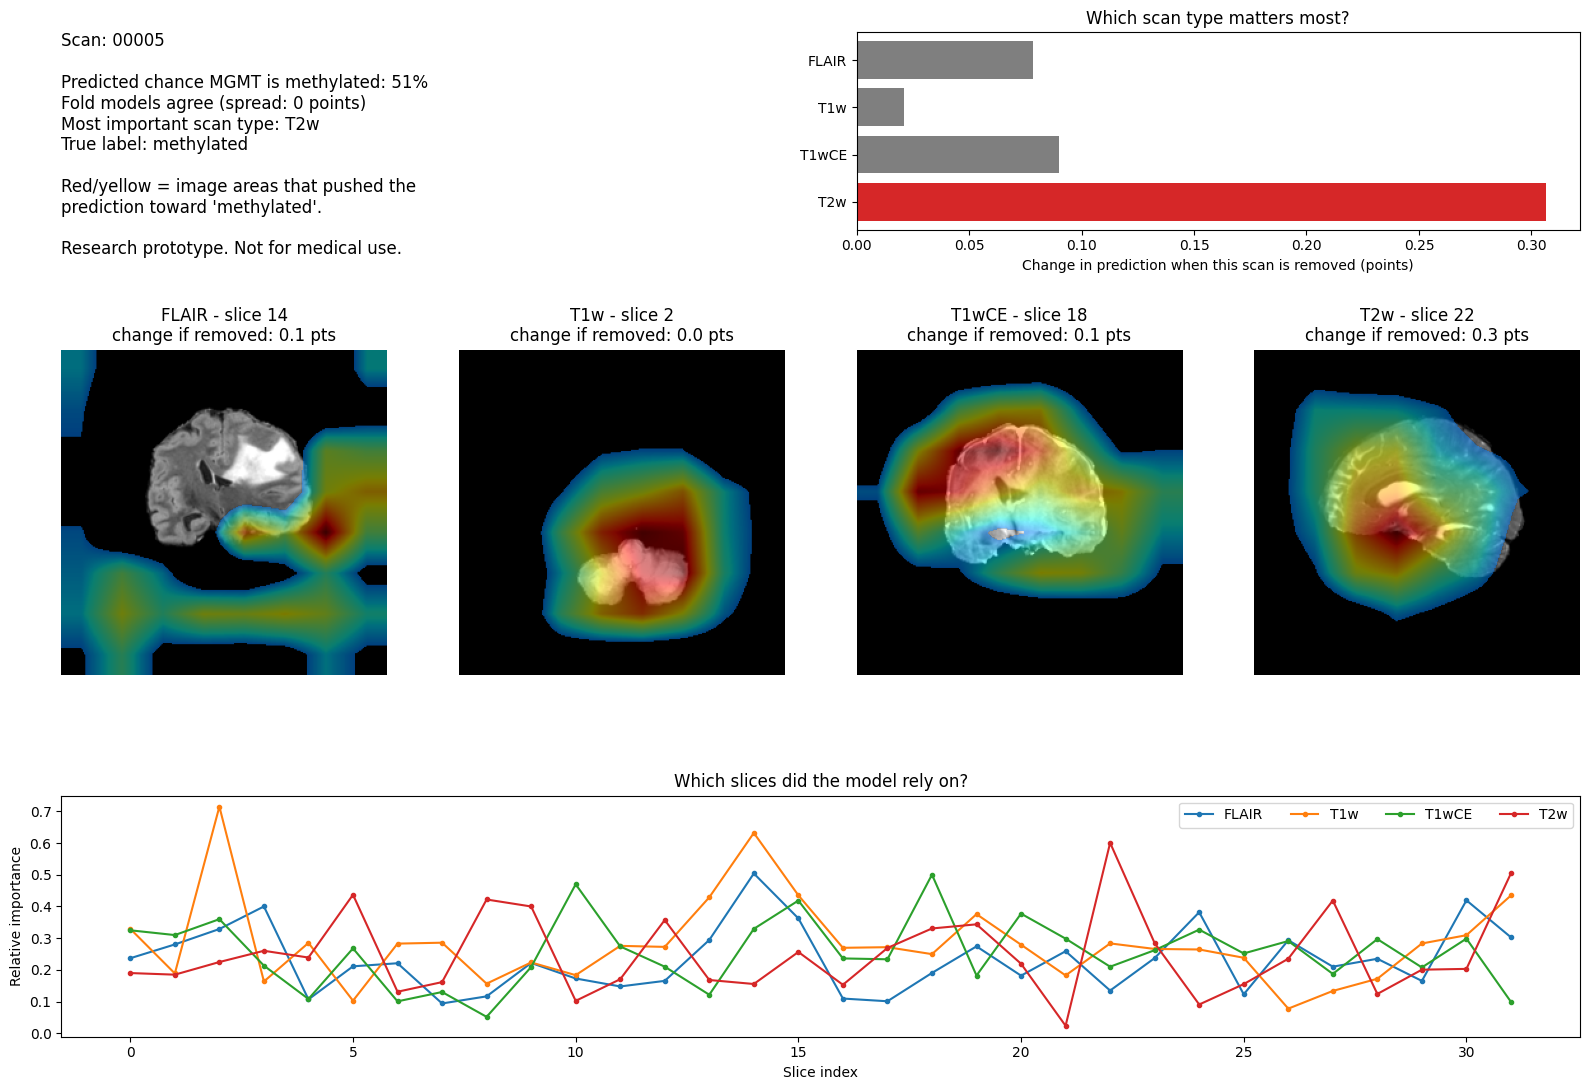

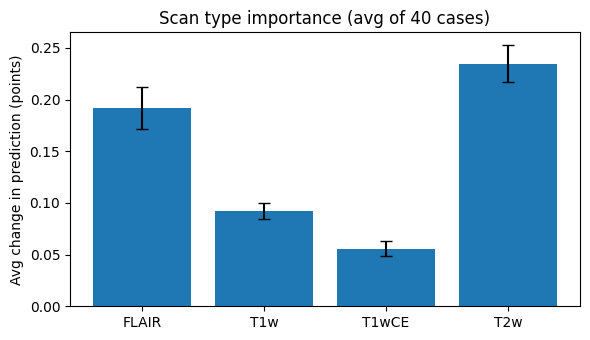

{'FLAIR': np.float64(0.19),
 'T1w': np.float64(0.09),
 'T1wCE': np.float64(0.06),
 'T2w': np.float64(0.23)}

In [27]:
# one case (scan_id must look like the value in df['BraTS21ID'], e.g. '00005')
res = explainer.explain(train_df, scan_id='00005', split='train')
explainer.plot(res, scan_id='00005', save_path='xai_00005.png')

# average view over many cases
explainer.global_modality_importance(train_df, train_df['BraTS21ID'].tolist()[:40])



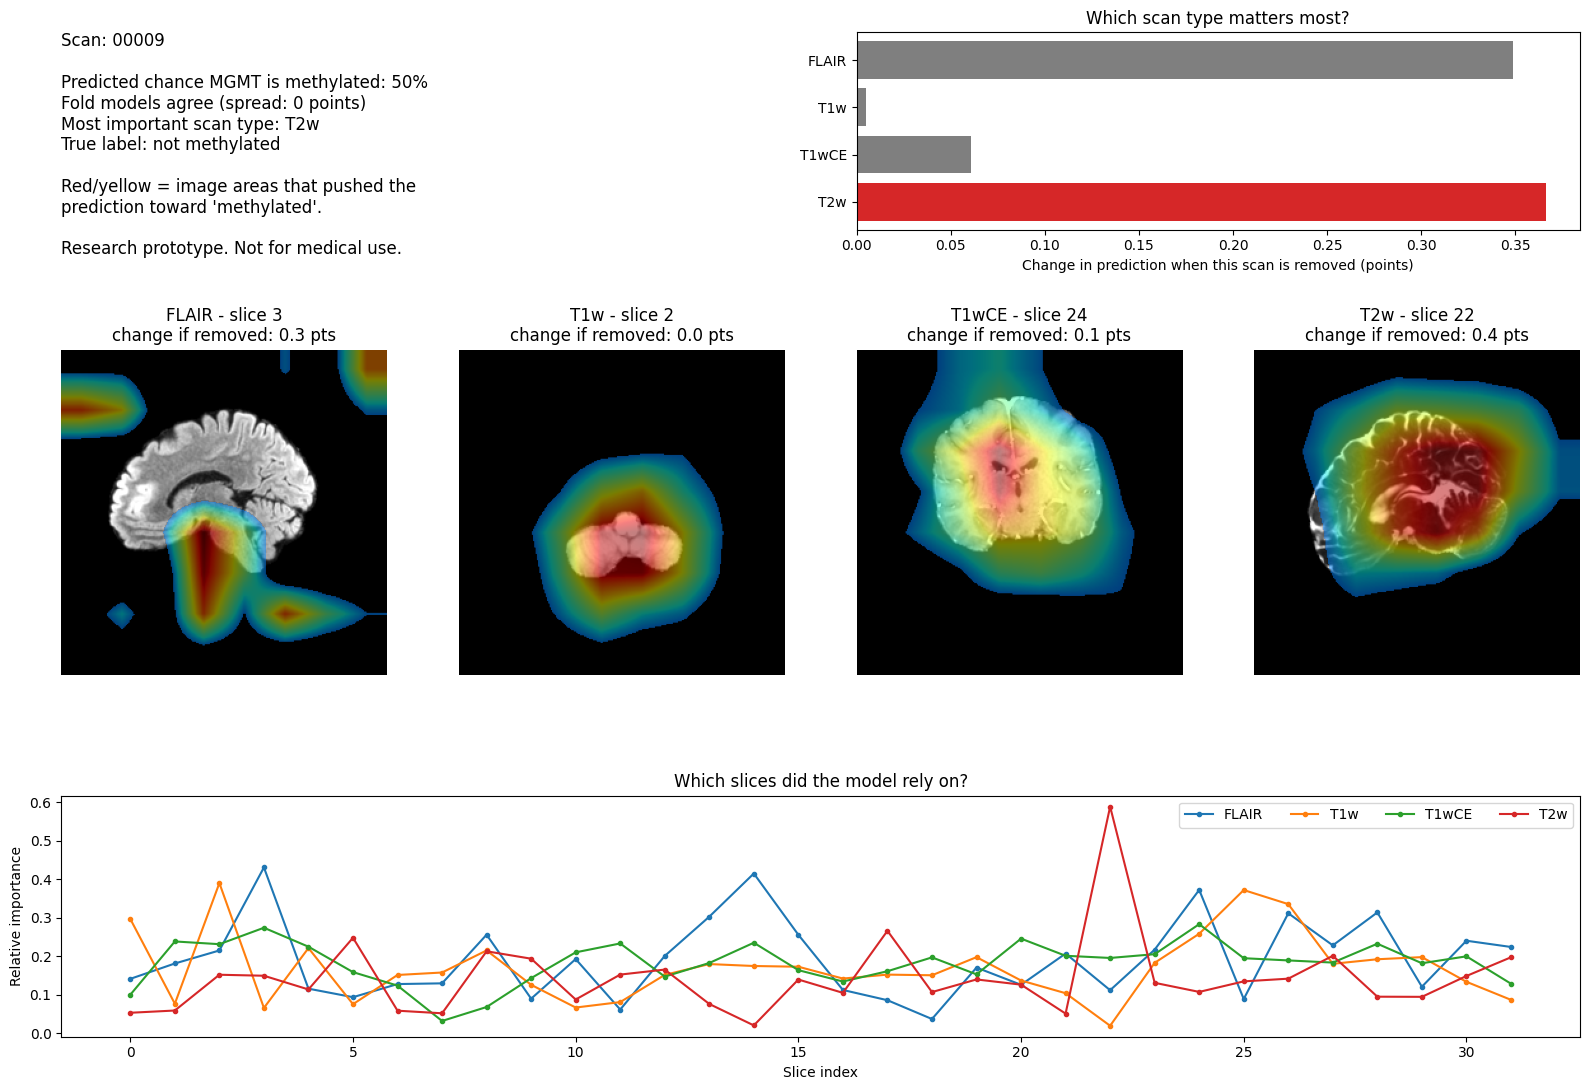

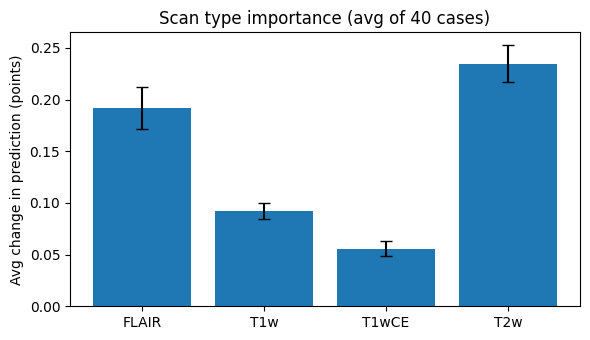

{'FLAIR': np.float64(0.19),
 'T1w': np.float64(0.09),
 'T1wCE': np.float64(0.06),
 'T2w': np.float64(0.23)}

In [28]:

# one case (scan_id must look like the value in df['BraTS21ID'], e.g. '00005')
res = explainer.explain(train_df, scan_id='00009', split='train')
explainer.plot(res, scan_id='00009', save_path='xai_00009.png')

# average view over many cases
explainer.global_modality_importance(train_df, train_df['BraTS21ID'].tolist()[:40])



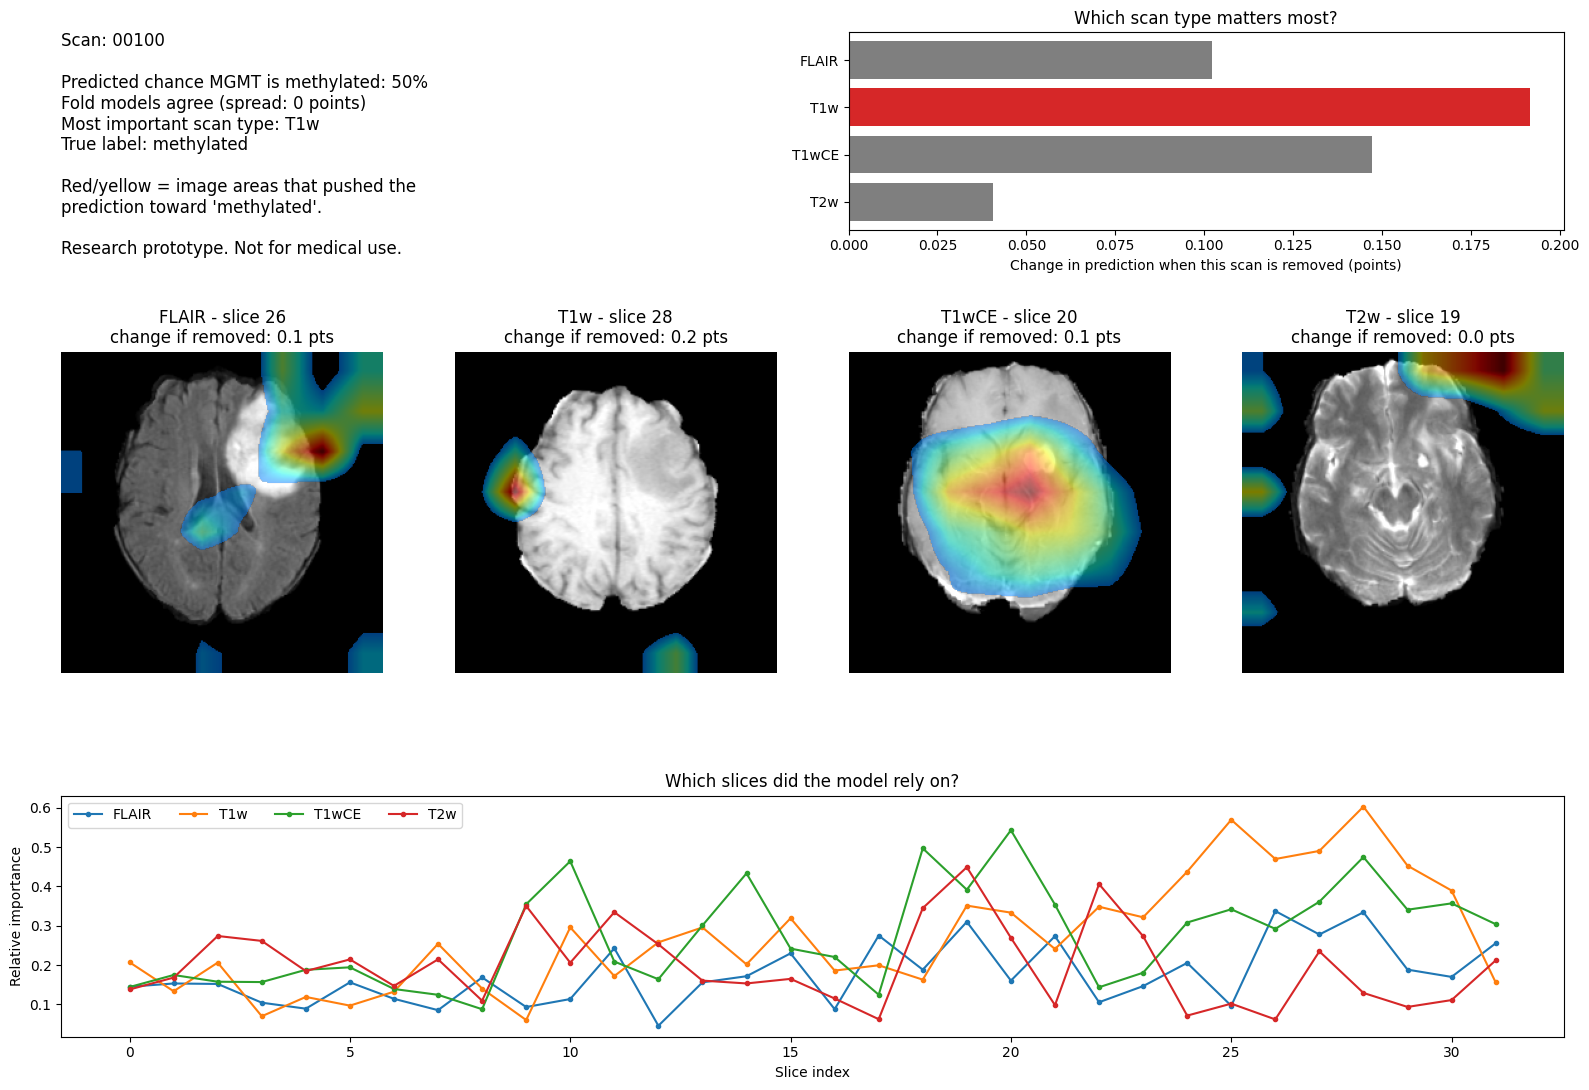

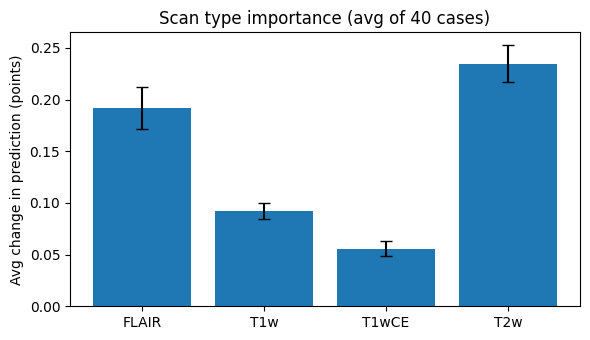

{'FLAIR': np.float64(0.19),
 'T1w': np.float64(0.09),
 'T1wCE': np.float64(0.06),
 'T2w': np.float64(0.23)}

In [32]:

# one case (scan_id must look like the value in df['BraTS21ID'], e.g. '00005')
res = explainer.explain(train_df, scan_id='00100', split='train')
explainer.plot(res, scan_id='00100', save_path='xai_00100.png')
# average view over many cases
explainer.global_modality_importance(train_df, train_df['BraTS21ID'].tolist()[:40])



Selected Encoder: resnet18
Loaded 1 fold model(s)


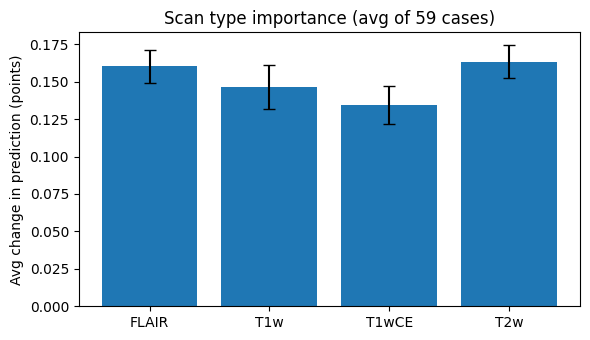

Selected Encoder: resnet18
Loaded 1 fold model(s)


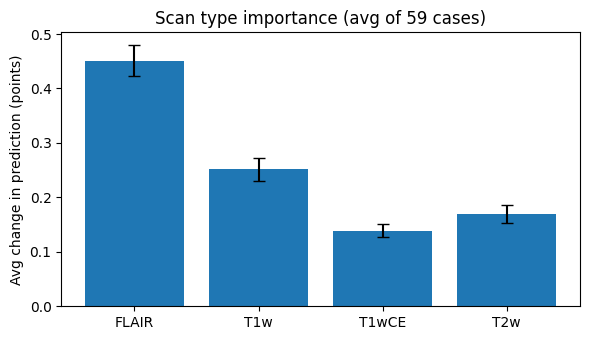

Selected Encoder: resnet18
Loaded 1 fold model(s)


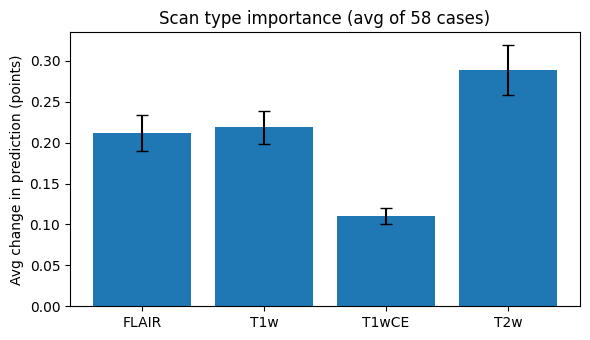

{'FLAIR': np.float64(0.21),
 'T1w': np.float64(0.22),
 'T1wCE': np.float64(0.11),
 'T2w': np.float64(0.29)}

In [35]:
# honest check: use ONE fold and ITS validation cases only
ex0 = MRIExplainer(weights_dir='/kaggle/input/2-5model', folds=[0], device='cuda')
ex0.global_modality_importance(val_df_fold0, val_df_fold0['BraTS21ID'].tolist())
# honest check: use ONE fold and ITS validation cases only
ex0 = MRIExplainer(weights_dir='/kaggle/input/2-5model', folds=[1], device='cuda')
ex0.global_modality_importance(val_df_fold1, val_df_fold1['BraTS21ID'].tolist())
# honest check: use ONE fold and ITS validation cases only
ex0 = MRIExplainer(weights_dir='/kaggle/input/2-5model', folds=[2], device='cuda')
ex0.global_modality_importance(val_df_fold2, val_df_fold2['BraTS21ID'].tolist())

In [37]:
"""
Model interpretation (XAI) for the brain-tumor MGMT models:
  - Model_3D            (3D CNN: MONAI resnet10 / resnet18 / efficientnet)
  - MRI25DFusionModel   (2.5D: per-slice CNN + slice attention + cross-modal attention)

WHAT IS IN HERE
----------------
1. Grad-CAM 3D              -> for Model_3D.        "Where in the volume did it look?"
2. Occlusion sensitivity 3D -> for Model_3D.        Slower, but does not trust gradients.
3. Attention extraction     -> for MRI25DFusionModel. "Which slices / which modality mattered?"
4. Grad-CAM 2D               -> for MRI25DFusionModel's slice CNN, run only on the
                                top-attention slices found in step 3.
                                "Where in that slice did it look?"
5. plot_3d_gradcam / plot_attention / plot_2d_gradcam -> quick matplotlib views.

WHY THESE, AND NOT SOMETHING ELSE
----------------------------------
- Grad-CAM needs one conv layer to hook. That layer is passed in explicitly
  (`target_layer=model.backbone.layer4`) -- no guessing of layer names inside
  this file, so it will not silently break if you change the backbone.
- Occlusion sensitivity does not use gradients at all: it blacks out a patch,
  re-runs the model, and reads the drop in predicted probability. Use it to
  sanity-check Grad-CAM -- if the two disagree a lot, trust occlusion more.
- The 2.5D model already computes attention internally, so use it first: it is
  free (no extra forward/backward passes) and tells you which of the ~60-80
  slices and which of the 4 modalities (FLAIR/T1w/T1wCE/T2w) drove the score,
  before you spend time on pixel-level maps.
- PyTorch's nn.TransformerEncoderLayer normally does NOT return attention
  weights (it uses a fused kernel that skips computing them). Section 3 below
  works around this with hooks -- see the comment there.

A SANITY CHECK WORTH RUNNING ONCE
----------------------------------
Randomize the model's weights layer by layer and re-run Grad-CAM. If the
heatmap barely changes, Grad-CAM is not actually reflecting what the network
learned for this architecture, and you should lean on occlusion sensitivity
and attention instead. (This is the "model parameter randomization" check
from Adebayo et al., 2018.)
"""
import math
from contextlib import contextmanager
from typing import Callable, List, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


# ════════════════════════════════════════════════════════════════════
# 1. GRAD-CAM -- works for both 3D (Model_3D) and 2D (slice CNN) since
#    it only cares about activation/gradient tensor shapes, not model type.
# ════════════════════════════════════════════════════════════════════
class GradCAM:
    """
    Generic Grad-CAM. Works on any conv layer, 2D or 3D.

    Usage (3D model):
        cam_fn = GradCAM(model, target_layer=model.backbone.layer4)
        heatmap = cam_fn(volume)             # volume: (1, 4, D, H, W)

    Usage (2D slice CNN):
        cam_fn = GradCAM(slice_encoder, target_layer=slice_encoder.backbone.layer4)
        heatmap = cam_fn(one_slice)          # one_slice: (1, 3, H, W)

    heatmap comes back the same spatial size as the input, values in [0, 1].
    """
    def __init__(self, model: nn.Module, target_layer: nn.Module):
        self.model = model
        self.activations: Optional[torch.Tensor] = None
        self.gradients: Optional[torch.Tensor] = None
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inp, out):
        self.activations = out.detach()

    def _save_gradient(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()

    def __call__(self, x: torch.Tensor) -> torch.Tensor:
        was_training = self.model.training
        self.model.eval()

        x = x.clone().requires_grad_(True)
        logit = self.model(x).reshape(-1)          # (B,) raw logit, single class
        self.model.zero_grad(set_to_none=True)
        logit.sum().backward()

        acts, grads = self.activations, self.gradients   # (B, C, *spatial)
        spatial_dims = tuple(range(2, acts.dim()))
        weights = grads.mean(dim=spatial_dims, keepdim=True)      # (B, C, 1[, 1[, 1]])
        cam = F.relu((weights * acts).sum(dim=1, keepdim=True))   # (B, 1, *spatial)

        target_size = x.shape[2:]
        mode = "trilinear" if len(target_size) == 3 else "bilinear"
        cam = F.interpolate(cam, size=target_size, mode=mode, align_corners=False)
        cam = cam[:, 0]                                            # (B, *spatial)

        # normalize each sample to [0, 1] independently
        flat = cam.view(cam.size(0), -1)
        cam_min = flat.min(dim=1, keepdim=True).values
        cam_max = flat.max(dim=1, keepdim=True).values
        flat = (flat - cam_min) / (cam_max - cam_min + 1e-8)
        cam = flat.view_as(cam)

        if was_training:
            self.model.train()
        return cam.detach()


# ════════════════════════════════════════════════════════════════════
# 2. OCCLUSION SENSITIVITY (3D) -- model-agnostic, no gradients.
#    Slides a cube over the volume, re-runs the model, records how much
#    the predicted probability drops. Slow (one forward pass per patch)
#    so keep patch_size/stride coarse for interactive use.
# ════════════════════════════════════════════════════════════════════
@torch.no_grad()
def occlusion_sensitivity_3d(model: nn.Module,
                              volume: torch.Tensor,
                              patch_size: int = 16,
                              stride: int = 16,
                              fill_value: float = 0.0,
                              batch_size: int = 8) -> torch.Tensor:
    """
    volume: (1, C, D, H, W) -- a single case.
    Returns a (D, H, W) map: how much the predicted probability of the
    positive class DROPS when that region is blanked out. Higher = the
    model relied on that region more.
    """
    model.eval()
    device = volume.device
    _, C, D, H, W = volume.shape

    baseline_prob = torch.sigmoid(model(volume).reshape(-1)).item()

    d_starts = list(range(0, D, stride))
    h_starts = list(range(0, H, stride))
    w_starts = list(range(0, W, stride))
    sensitivity = torch.zeros(len(d_starts), len(h_starts), len(w_starts))

    coords = [(di, hi, wi) for di in range(len(d_starts))
              for hi in range(len(h_starts)) for wi in range(len(w_starts))]

    for batch_start in range(0, len(coords), batch_size):
        batch_coords = coords[batch_start: batch_start + batch_size]
        batch = volume.repeat(len(batch_coords), 1, 1, 1, 1).clone()
        for i, (di, hi, wi) in enumerate(batch_coords):
            d0, h0, w0 = d_starts[di], h_starts[hi], w_starts[wi]
            d1, h1, w1 = min(d0 + patch_size, D), min(h0 + patch_size, H), min(w0 + patch_size, W)
            batch[i, :, d0:d1, h0:h1, w0:w1] = fill_value
        probs = torch.sigmoid(model(batch.to(device)).reshape(-1)).cpu()
        for i, (di, hi, wi) in enumerate(batch_coords):
            sensitivity[di, hi, wi] = baseline_prob - probs[i].item()

    # upsample the coarse grid back to full volume resolution
    sensitivity = sensitivity.unsqueeze(0).unsqueeze(0)
    sensitivity = F.interpolate(sensitivity, size=(D, H, W), mode="trilinear", align_corners=False)
    return sensitivity[0, 0]


# ════════════════════════════════════════════════════════════════════
# 3. ATTENTION EXTRACTION for MRI25DFusionModel
#
#    nn.TransformerEncoderLayer normally runs a fused kernel that never
#    computes attention weights (calls self_attn with need_weights=False
#    internally). The trick: a forward_pre_hook rewrites the kwargs to
#    force need_weights=True right before self_attn runs, and a
#    forward_hook grabs the result. Both are removed right after.
# ════════════════════════════════════════════════════════════════════
def _force_need_weights(module, args, kwargs):
    kwargs["need_weights"] = True
    kwargs["average_attn_weights"] = True     # -> (B, N, N), averaged over heads
    return args, kwargs


@contextmanager
def _capture_attention(transformer_encoder: nn.TransformerEncoder, sink: list):
    # When a padding mask is given, PyTorch's TransformerEncoder switches to an
    # internal "nested tensor" fast path that silently DROPS padded positions,
    # which shrinks the attention matrix and shifts every slice's index. Turn
    # it off for the duration of this call so shapes always stay (N+1, N+1)
    # and slice index i in the output always means slice i in your input.
    had_flag = hasattr(transformer_encoder, "use_nested_tensor")
    old_value = transformer_encoder.use_nested_tensor if had_flag else None
    if had_flag:
        transformer_encoder.use_nested_tensor = False

    handles = []
    for layer in transformer_encoder.layers:
        handles.append(layer.self_attn.register_forward_pre_hook(_force_need_weights, with_kwargs=True))
        handles.append(layer.self_attn.register_forward_hook(lambda m, i, o: sink.append(o[1])))
    try:
        yield
    finally:
        for h in handles:
            h.remove()
        if had_flag:
            transformer_encoder.use_nested_tensor = old_value


@torch.no_grad()
def explain_25d_case(model, modalities: Sequence[torch.Tensor],
                     masks: Optional[Sequence[torch.Tensor]] = None,
                     modality_names: Sequence[str] = ("FLAIR", "T1w", "T1wCE", "T2w")):
    """
    Run one case through MRI25DFusionModel and pull out:
      - the prediction
      - per-modality slice attention: how much the [CLS] token attended to
        each slice (last transformer layer only -> most decision-relevant)
      - cross-modality attention: how much each modality attended to the
        others, averaged into one "importance per modality" score

    modalities: list of 4 tensors, each (1, N_m, 3, H, W)  (batch size 1)
    Returns a dict -- see the keys below.
    """
    model.eval()
    if masks is None:
        masks = [None] * len(modalities)

    slice_attn_per_modality = []   # one (N_m,) tensor per modality
    modality_importance = None

    for slices, pooler, mask in zip(modalities, model.slice_poolers, masks):
        B, N_m, C, H, W = slices.shape
        flat = slices.view(B * N_m, C, H, W)
        feats = model.slice_encoder(flat).view(B, N_m, -1)

        # -- slice attention inside this modality --
        x = feats + pooler.pos_emb(torch.arange(N_m, device=feats.device))
        cls = pooler.cls_token.expand(B, -1, -1)
        x = torch.cat([cls, x], dim=1)
        kpm = None
        if mask is not None:
            cls_mask = torch.zeros(B, 1, dtype=torch.bool, device=x.device)
            kpm = torch.cat([cls_mask, mask], dim=1)

        sink = []
        with _capture_attention(pooler.transformer, sink):
            pooled_full = pooler.transformer(x, src_key_padding_mask=kpm)
        pooled = pooled_full[:, 0]

        # last layer's attention from [CLS] (query 0) to every slice (keys 1..N)
        last_layer_attn = sink[-1]                       # (B, N+1, N+1)
        cls_to_slices = last_layer_attn[:, 0, 1:]         # (B, N_m)
        slice_attn_per_modality.append(cls_to_slices[0].cpu())
        pooler._last_pooled = pooled                      # stash for fusion step below

    modality_vecs = [pooler._last_pooled for pooler in model.slice_poolers]

    # -- cross-modality attention --
    x = torch.stack(modality_vecs, dim=1)
    ids = torch.arange(x.size(1), device=x.device)
    x = x + model.fusion.mod_emb(ids)
    sink = []
    with _capture_attention(model.fusion.transformer, sink):
        fused_seq = model.fusion.transformer(x)
    fused = fused_seq.mean(dim=1)
    fusion_attn = sink[-1][0].cpu()       # (num_modalities, num_modalities)
    # "how much attention did each modality receive overall" (column mean)
    modality_importance = fusion_attn.mean(dim=0)

    logit = model.head(fused).reshape(-1)
    prob = torch.sigmoid(logit).item()

    return {
        "prob": prob,
        "logit": logit.item(),
        "slice_attention": dict(zip(modality_names, slice_attn_per_modality)),  # {name: (N_m,)}
        "modality_importance": dict(zip(modality_names, modality_importance.tolist())),
        "fusion_attention_matrix": fusion_attn,   # (4,4), row=query modality, col=key modality
    }


def top_attended_slices(slice_attention: torch.Tensor, k: int = 3) -> List[int]:
    """Indices of the k most-attended slices for one modality (for step 4)."""
    return torch.topk(slice_attention, k=min(k, slice_attention.numel())).indices.tolist()


# ════════════════════════════════════════════════════════════════════
# 4. 2D Grad-CAM for the slice CNN, meant to be run only on the
#    top_attended_slices() from step 3 -- not all 60-80 slices.
# ════════════════════════════════════════════════════════════════════
def get_slice_encoder_target_layer(slice_encoder) -> nn.Module:
    """Last conv block, for either backbone the model can use."""
    backbone = slice_encoder.backbone
    if hasattr(backbone, "layer4"):          # resnet18
        return backbone.layer4[-1]
    if hasattr(backbone, "features"):        # convnext_tiny
        return backbone.features[-1]
    raise ValueError("Unrecognized backbone -- pass target_layer explicitly instead.")


# ════════════════════════════════════════════════════════════════════
# 5. Plotting helpers
# ════════════════════════════════════════════════════════════════════
def plot_3d_gradcam(volume_channel: np.ndarray, heatmap: np.ndarray, slice_idx: Optional[int] = None,
                    title: str = "Grad-CAM"):
    """volume_channel, heatmap: (D, H, W) numpy arrays. Shows the middle axial slice by default."""
    if slice_idx is None:
        slice_idx = volume_channel.shape[0] // 2
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(volume_channel[slice_idx], cmap="gray")
    axes[0].set_title("MRI slice")
    axes[0].axis("off")
    axes[1].imshow(volume_channel[slice_idx], cmap="gray")
    axes[1].imshow(heatmap[slice_idx], cmap="jet", alpha=0.45)
    axes[1].set_title(title)
    axes[1].axis("off")
    fig.tight_layout()
    return fig


def plot_2d_gradcam(image_hw3: np.ndarray, heatmap: np.ndarray, title: str = "Grad-CAM"):
    """image_hw3: (H, W, 3) numpy in [0,1]. heatmap: (H, W)."""
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(image_hw3)
    axes[0].set_title("slice"); axes[0].axis("off")
    axes[1].imshow(image_hw3)
    axes[1].imshow(heatmap, cmap="jet", alpha=0.45)
    axes[1].set_title(title); axes[1].axis("off")
    fig.tight_layout()
    return fig


def plot_attention(result: dict, modality: str):
    """Bar chart of per-slice attention for one modality, from explain_25d_case()."""
    attn = result["slice_attention"][modality].numpy()
    fig, ax = plt.subplots(figsize=(8, 2.5))
    ax.bar(range(len(attn)), attn)
    ax.set_title(f"{modality} — slice attention (prob={result['prob']:.3f})")
    ax.set_xlabel("slice index")
    fig.tight_layout()
    return fig

Selected Encoder: resnet18
0.5079962015151978 {'FLAIR': 0.26500535011291504, 'T1w': 0.2886897623538971, 'T1wCE': 0.2712324559688568, 'T2w': 0.17507243156433105}


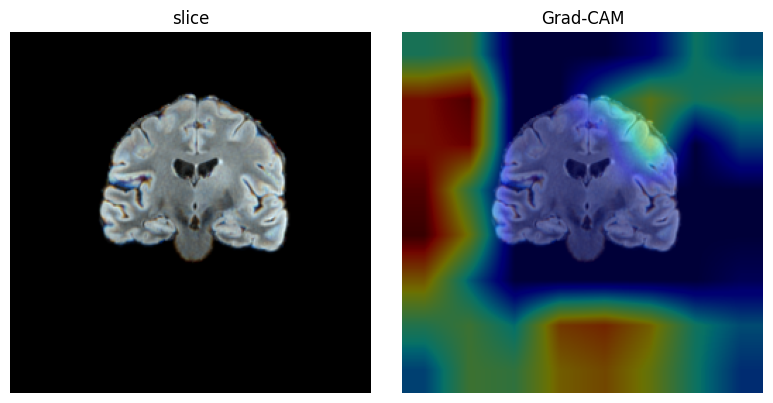

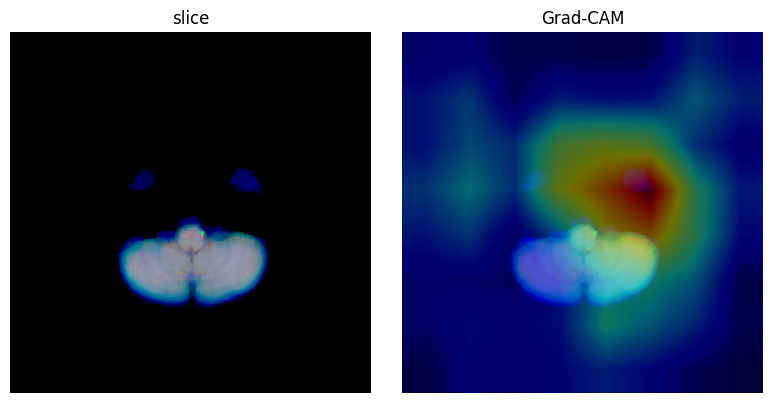

In [38]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
train_df = pd.read_csv(cfg.paths.train_root)
train_df['BraTS21ID'] = train_df['BraTS21ID'].map('{:05}'.format)

path = '/kaggle/input/2-5model/best_model_fold0.pth'
model = MRI25DFusionModel(d=256, nhead=4, num_layers=2, num_modalities=4, max_slices=32)
model.load_state_dict(torch.load(path, map_location=device))
model.to(device)
model.eval()

# build the case the same way training did
val_transform = get_val_transform(num_slices=NUM_SLICES, image_size=IMAGE_SIZE)
case_df = train_df[train_df['BraTS21ID'] == '00000']
ds = BrainMRIDataset(case_df, scan_ids=case_df['BraTS21ID'], split='train', augmentation=val_transform)
modalities, label = ds[0]                                     # list of 4, each (N_m, 3, H, W)
modalities = [m.unsqueeze(0).to(device) for m in modalities]  # add batch dim -> (1, N_m, 3, H, W)

result = explain_25d_case(model, modalities)
print(result['prob'], result['modality_importance'])

top_idx = top_attended_slices(result['slice_attention']['FLAIR'], k=3)
target_layer = get_slice_encoder_target_layer(model.slice_encoder)
cam_fn = GradCAM(model.slice_encoder, target_layer=target_layer)

slice_img = modalities[0][:, top_idx[0]]      # (1, 3, H, W)
heatmap = cam_fn(slice_img)                    # (1, H, W)

img = slice_img[0].permute(1, 2, 0).detach().cpu().numpy()
img = (img - img.min()) / (img.max() - img.min() + 1e-8)   # normalize for display
fig = plot_2d_gradcam(img, heatmap[0].cpu().numpy())


slice_img = modalities[1][:, top_idx[0]]      # (1, 3, H, W)
heatmap = cam_fn(slice_img)                    # (1, H, W)

img = slice_img[0].permute(1, 2, 0).detach().cpu().numpy()
img = (img - img.min()) / (img.max() - img.min() + 1e-8)   # normalize for display
fig = plot_2d_gradcam(img, heatmap[0].cpu().numpy())
